使用SMC, KUL和Pelka数据的CRC分析\
由于PM数据的低质量, 准备转而仅分析CRC数据集

In [1]:
# import modules
from pathlib import Path
from collections import Counter
import sys, gc, random
import numpy as np
import pandas as pd
from scipy.stats import median_abs_deviation
import matplotlib.pyplot as plt
import anndata as ad
import scanpy as sc
import scvi

# setting directory
PROJECT_DIR = Path.home() / "project/crc-pm"
CODE_DIR = PROJECT_DIR / "code"
OUTDIR = PROJECT_DIR / "result/fork1-OnlyCRC"
FIGDIR = OUTDIR / "figures"
sc.settings.figdir = FIGDIR
# enabling import src
sys.path.insert(0, str(CODE_DIR))
# enabling import loaders
sys.path.insert(0, str(CODE_DIR / "fork1-OnlyCRC/loaders"))
import Lee_2020_NatGen as lee
import Pelka_2021_Cell as pelka

# other
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
scvi.settings.seed = SEED
GTF_VERSION = "GRCh38.84"

Seed set to 42


读取adata, 并取交集\
对于相同

In [2]:
adata_dict = {
    "Lee_2020_NatGen": lee.load(),
    "Pelka_2021_Cell": pelka.load(),
}

# only keep gene that exists in all data set
gene_counter = Counter()
for adata in adata_dict.values():
    if not adata.var_names.is_unique:
        raise ValueError("adata.var_names must be unique.")
    gene_counter.update(adata.var_names)
keep_genes = {gene for gene, count in gene_counter.items() if count == len(adata_dict)}

# concatenate
concat_list = [adata[:, adata.var_names.isin(keep_genes)].copy() for adata in adata_dict.values()]
# 合并注释, 注意merge_var会被用于多个对象, 比如varm, 而后者是字典, 所以需要专门处理
def merge_var(x):
    if isinstance(x[0], pd.DataFrame):
        # 传入一个var的list, 然后合并, 按照第一列(index)分组, 取第一个非空的值
        return pd.concat(x).groupby(level=0, sort=False).first()
    # 不处理varm, varp等
    return {}
adata = ad.concat(
    concat_list,
    axis="obs",
    join="outer", # 虽然这里是outer, 但是前面筛选过了, 仍然是交集
    merge=merge_var,
    fill_value=0,
)
print(adata.var.isna().sum())
adata.obs["Study_Assay"] = adata.obs["Study"].astype(str) + "_" + adata.obs["Assay"].astype(str)
print(adata.shape)
del adata_dict, concat_list
gc.collect()

/home/zhekai/miniconda3/envs/pm/lib/python3.13/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/zhekai/miniconda3/envs/pm/lib/python3.13/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/zhekai/miniconda3/envs/pm/lib/python3.13/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


gene_name       0
gene_id         0
gene_biotype    0
dtype: int64
(313416, 32833)


717

QC: 每个 Study 内部进行 MAD QC

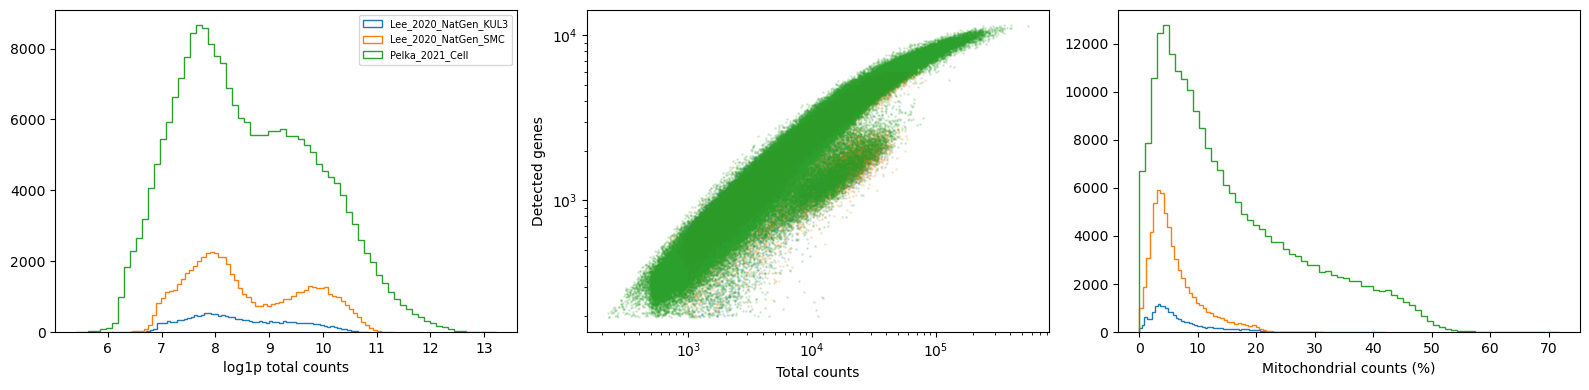

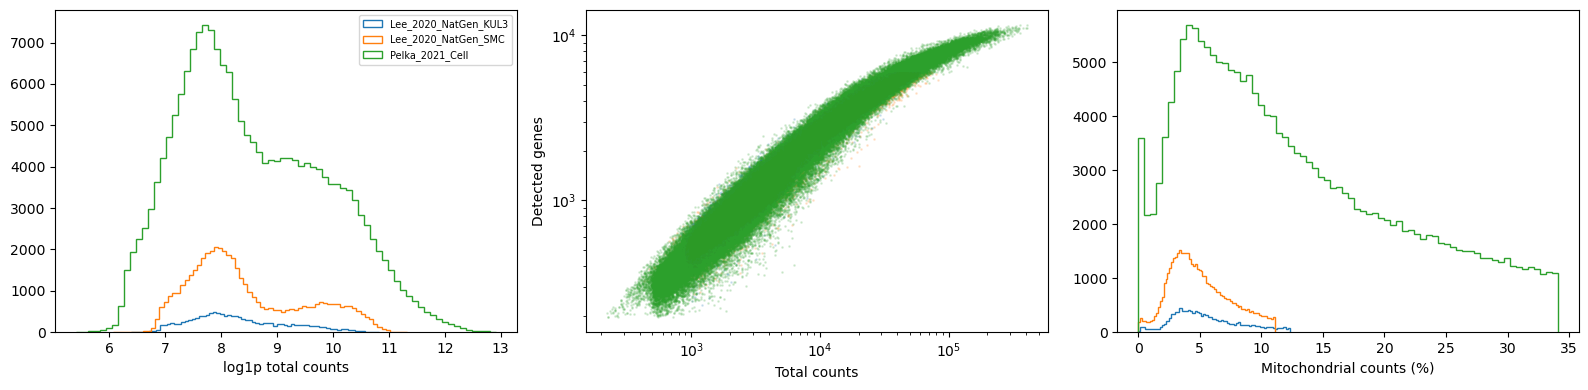

In [3]:
# 标记基因
adata.var["mt"] = adata.var["gene_name"].str.startswith("MT-")
adata.var["ribo"] = adata.var["gene_name"].str.startswith(("RPS", "RPL"))
adata.var["hb"] = adata.var["gene_name"].str.contains(r"^HB[ABDEGMQZ]\d*(?!\w)", regex=True)
sc.pp.calculate_qc_metrics(adata, layer="counts", qc_vars=["mt", "ribo", "hb"],
                           percent_top=[20], log1p=True, inplace=True)
def outlier(metric, nmads):
    values = adata.obs[metric]
    grouped = adata.obs.groupby("Study", observed=True)[metric]
    med = grouped.transform("median")
    mad = grouped.transform(lambda x: median_abs_deviation(x, nan_policy="raise"))
    return (values < med - nmads * mad) | (values > med + nmads * mad)
# 去除outlier, 不同cutoff, mt设置为40%
adata.obs["outlier"] = (outlier("log1p_total_counts", 5) | outlier("log1p_n_genes_by_counts", 5)
                         | outlier("pct_counts_in_top_20_genes", 5))
adata.obs["mt_outlier"] = outlier("pct_counts_mt", 3) | (adata.obs["pct_counts_mt"] > 40)
adata.obs["qc_outlier"] = adata.obs["outlier"] | adata.obs["mt_outlier"]
# 可视化qc_plot, 传入obs TODO 看看怎么改进 + 复用
def qc_plot(obs):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for study, frame in obs.groupby("Study", observed=True):
        axes[0].hist(np.log1p(frame["total_counts"]), bins=70, histtype="step", label=study)
        axes[1].scatter(frame["total_counts"], frame["n_genes_by_counts"], s=1, alpha=0.15)
        axes[2].hist(frame["pct_counts_mt"], bins=70, histtype="step")
    axes[0].set_xlabel("log1p total counts"); axes[0].legend(fontsize=7)
    axes[1].set(xscale="log", yscale="log", xlabel="Total counts", ylabel="Detected genes")
    axes[2].set_xlabel("Mitochondrial counts (%)")
    fig.tight_layout()
# 生成audit备用
audit = adata.obs.copy()
audit["doublet_score"] = np.nan
audit["predicted_doublet"] = False
audit["scrublet_status"] = "not_run_qc_removed"
audit["scrublet_threshold"] = np.nan
qc_plot(audit)
adata = adata[~adata.obs["qc_outlier"]].copy()
# 去除总count数<20的基因
n_detected = np.asarray((adata.layers["counts"] > 0).sum(axis=0)).ravel()
adata.var["n_cells_after_cell_qc"] = n_detected
adata = adata[:, n_detected >= 20].copy()
qc_plot(adata.obs)

运行 Scrublet 去除双细胞
少于 200 个细胞时跳过，分数 NaN、预测 False

In [4]:
# 设置初始条件
adata.obs["doublet_score"] = np.nan
adata.obs["predicted_doublet"] = False
adata.obs["scrublet_status"] = 'pending'
adata.obs["scrublet_threshold_per_sample"] = np.nan
scrublet_rows = []
# 按照 Glob_Sample 将 AnnData 分成多个样本
# 对每个样本独立运行 Scrublet 检测 doublet, 将结果写回原始 adata
for sample_no, (sample, idx) in enumerate(adata.obs.groupby("Glob_Sample", observed=True,sort = False).indices.items()):
    # 正常groupby返回是grouby对象, indices返回字典, 值是每个分组对应的整数行位置, 随后取键值对
    idx = np.asarray(idx)
    names, n_cells = adata.obs_names[idx], len(idx)
    print(f"{sample}: {n_cells} cells", flush=True)
    # 设置主成分
    n_pcs = 10 if n_cells < 500 else 20 if n_cells < 1000 else 30
    row = dict(Glob_Sample=sample, n_cells=n_cells, n_pcs=n_pcs if n_cells >= 200 else 0,
               threshold=np.nan, predicted_doublets=0, status="skipped_lt200",)
    if n_cells < 200:
        adata.obs.loc[names, "scrublet_status"] = row["status"]
    else:
        # 提取一个样本切片
        tmp = ad.AnnData(X=adata.layers["counts"][idx].copy(),
                         obs=pd.DataFrame(index=names), var=pd.DataFrame(index=adata.var_names))
        sc.pp.scrublet(tmp, expected_doublet_rate=0.05, sim_doublet_ratio=2.0,
                       mean_center=False, # 拒绝中心化, 保持大多数零值, 保持csr
                       n_prin_comps=n_pcs, random_state=0)
        info = tmp.uns["scrublet"]
        threshold = info["threshold"]
        scores = tmp.obs["doublet_score"].to_numpy()
        simulated = np.asarray(info["doublet_scores_sim"])
        predicted = tmp.obs["predicted_doublet"].to_numpy(dtype=bool)
        # 赋值
        adata.obs.loc[names, "doublet_score"] = scores
        adata.obs.loc[names, "predicted_doublet"] = predicted
        adata.obs.loc[names, "scrublet_threshold_per_sample"] = threshold
        adata.obs.loc[names, "scrublet_status"] = "detected"
        # 更新row
        row['threshold'] = threshold
        row['predicted_doublets'] = predicted.sum()
        row['status']="screened"
        del tmp
        gc.collect()
    scrublet_rows.append(row)
scrublet_summary = pd.DataFrame(scrublet_rows)
print(scrublet_summary)

Lee_2020_NatGen_KUL3-KUL01-T: 1677 cells
Lee_2020_NatGen_KUL3-KUL19-T: 2791 cells
Lee_2020_NatGen_KUL3-KUL21-T: 1618 cells
Lee_2020_NatGen_KUL3-KUL28-T: 351 cells
Lee_2020_NatGen_KUL3-KUL30-T: 299 cells
Lee_2020_NatGen_KUL3-KUL31-T: 58 cells
Lee_2020_NatGen_KUL3-KUL01-N: 1434 cells
Lee_2020_NatGen_KUL3-KUL19-N: 1192 cells
Lee_2020_NatGen_KUL3-KUL21-N: 916 cells
Lee_2020_NatGen_KUL3-KUL28-N: 532 cells
Lee_2020_NatGen_KUL3-KUL30-N: 1005 cells
Lee_2020_NatGen_KUL3-KUL31-N: 1141 cells
Lee_2020_NatGen_SMC-SMC01-T: 2435 cells
Lee_2020_NatGen_SMC-SMC02-T: 1257 cells
Lee_2020_NatGen_SMC-SMC03-T: 1709 cells
Lee_2020_NatGen_SMC-SMC04-T: 1509 cells
Lee_2020_NatGen_SMC-SMC05-T: 615 cells
Lee_2020_NatGen_SMC-SMC06-T: 1352 cells
Lee_2020_NatGen_SMC-SMC07-T: 3273 cells
Lee_2020_NatGen_SMC-SMC08-T: 1764 cells
Lee_2020_NatGen_SMC-SMC09-T: 3075 cells
Lee_2020_NatGen_SMC-SMC10-T: 1772 cells
Lee_2020_NatGen_SMC-SMC11-T: 1435 cells
Lee_2020_NatGen_SMC-SMC14-T: 1546 cells
Lee_2020_NatGen_SMC-SMC15-T: 1684 c

                      input_cells  qc_removed  doublet_removed    kept
Study                                                                 
Lee_2020_NatGen_KUL3        17990        4976               34   12980
Lee_2020_NatGen_SMC         63689       14042              105   49542
Pelka_2021_Cell            231737       35341              414  195982


30

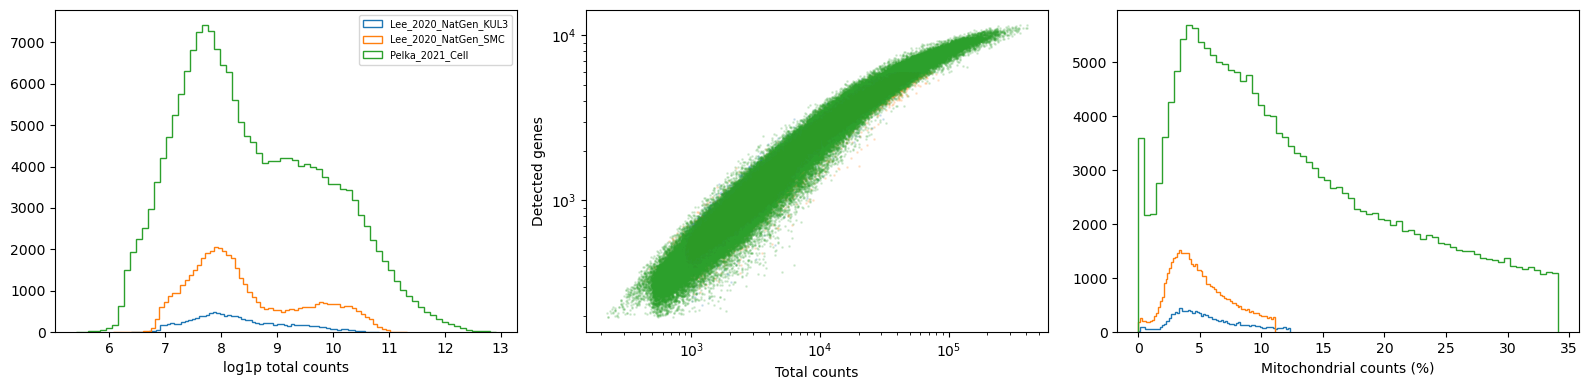

In [5]:
for col in ["doublet_score", "predicted_doublet", "scrublet_status", "scrublet_threshold_per_sample"]:
    audit.loc[adata.obs_names, col] = adata.obs[col].to_numpy()
audit["kept"] = ~audit["qc_outlier"] & ~audit["predicted_doublet"]
audit["qc_removed"] = audit["qc_outlier"]
audit["doublet_removed"] = ~audit["qc_outlier"] & audit["predicted_doublet"]
summary = audit.groupby('Study', observed=True).agg(
    input_cells=("kept", "size"), # 统计行数
    qc_removed=("qc_removed", "sum"),
    doublet_removed=("doublet_removed", "sum"),
    kept=("kept", "sum"))
print(summary)
adata = adata[~adata.obs["predicted_doublet"]].copy()
qc_plot(adata.obs)  # 以过滤前计算的 QC 指标展示保留细胞
adata.write_h5ad(OUTDIR / "qc.h5ad", compression="lzf")
del audit
gc.collect()

## CRC、normal 各选 4,000 HVG，取并集

In [6]:
# 候选非mt, 核和血红蛋白的protein coding基因
candidate = (
    adata.var["gene_biotype"].eq("protein_coding")
    &
    ~adata.var["mt"]
    &
    ~adata.var["ribo"]
    &
    ~adata.var["hb"])

for tissue in ["crc", "normal"]:
    adata.var[f"{tissue}_hvg"] = False
    idx = adata.obs["Tissue"] == tissue
    tissue_adata = adata[idx].copy()
    sc.pp.highly_variable_genes(
        tissue_adata, n_top_genes=4000, flavor="seurat_v3", layer="counts",
        batch_key="Study_Assay", subset=False, inplace=True)
    adata.var.loc[tissue_adata.var_names, f"{tissue}_hvg"] = tissue_adata.var["highly_variable"]
adata.var["highly_variable"] = adata.var[["crc_hvg", "normal_hvg"]].any(axis=1)
print("CRC:", adata.var.crc_hvg.sum(), "normal:", adata.var.normal_hvg.sum(), "union:", adata.var["highly_variable"].sum())

CRC: 4000 normal: 4000 union: 5455


scVI进行去批次 + 潜空间表示

In [7]:
training_genes = adata.var_names[adata.var["highly_variable"]].copy()
# 重建一个adata对象
adata_scvi = adata[:, training_genes].copy()
# 设置scVI
scvi.model.SCVI.setup_anndata(adata_scvi, layer="counts", batch_key="Study_Assay")
model_scvi = scvi.model.SCVI(adata_scvi, n_latent=20, n_layers=2, gene_likelihood="nb", dispersion="gene")
# # 设置最大epoch并训练
# max_epochs_scvi = int(np.min([round((20000 / adata_scvi.n_obs) * 400), 400]))
# model_scvi.train(max_epochs=max_epochs_scvi, early_stopping=True, batch_size=512)
# # 保存
# model_scvi.save(OUTDIR / "scvi_model", overwrite=True)
# 读取
model_scvi = scvi.model.SCVI.load(OUTDIR / "scvi_model", adata=adata_scvi)
# 拿latent空间表示
adata.obsm["X_scVI"] = model_scvi.get_latent_representation(adata=adata_scvi, batch_size=512)
del model_scvi, adata_scvi
gc.collect()

INFO     File /home/zhekai/project/crc-pm/result/fork1-OnlyCRC/scvi_model/model.pt already downloaded              


51459

log1p, umap和leiden

In [ ]:
# 做log1p转换
adata.layers["log1p"] = adata.layers["counts"].astype(np.float32).copy()
sc.pp.normalize_total(adata, layer="log1p", target_sum=10000)
sc.pp.log1p(adata, layer="log1p")

# 算邻接图
sc.pp.neighbors(adata, use_rep="X_scVI", n_neighbors=20, metric="cosine", random_state=SEED)
sc.tl.umap(adata, min_dist=0.25, random_state=SEED)
# 先进行较低分辨率的聚类
for resolution in [0.02, 0.05, 0.1 ,0.25, 0.5,]:
    sc.tl.leiden(adata, resolution=resolution, key_added=f"leiden_{resolution}",
                 random_state=SEED, flavor="igraph", directed=False, n_iterations=2)

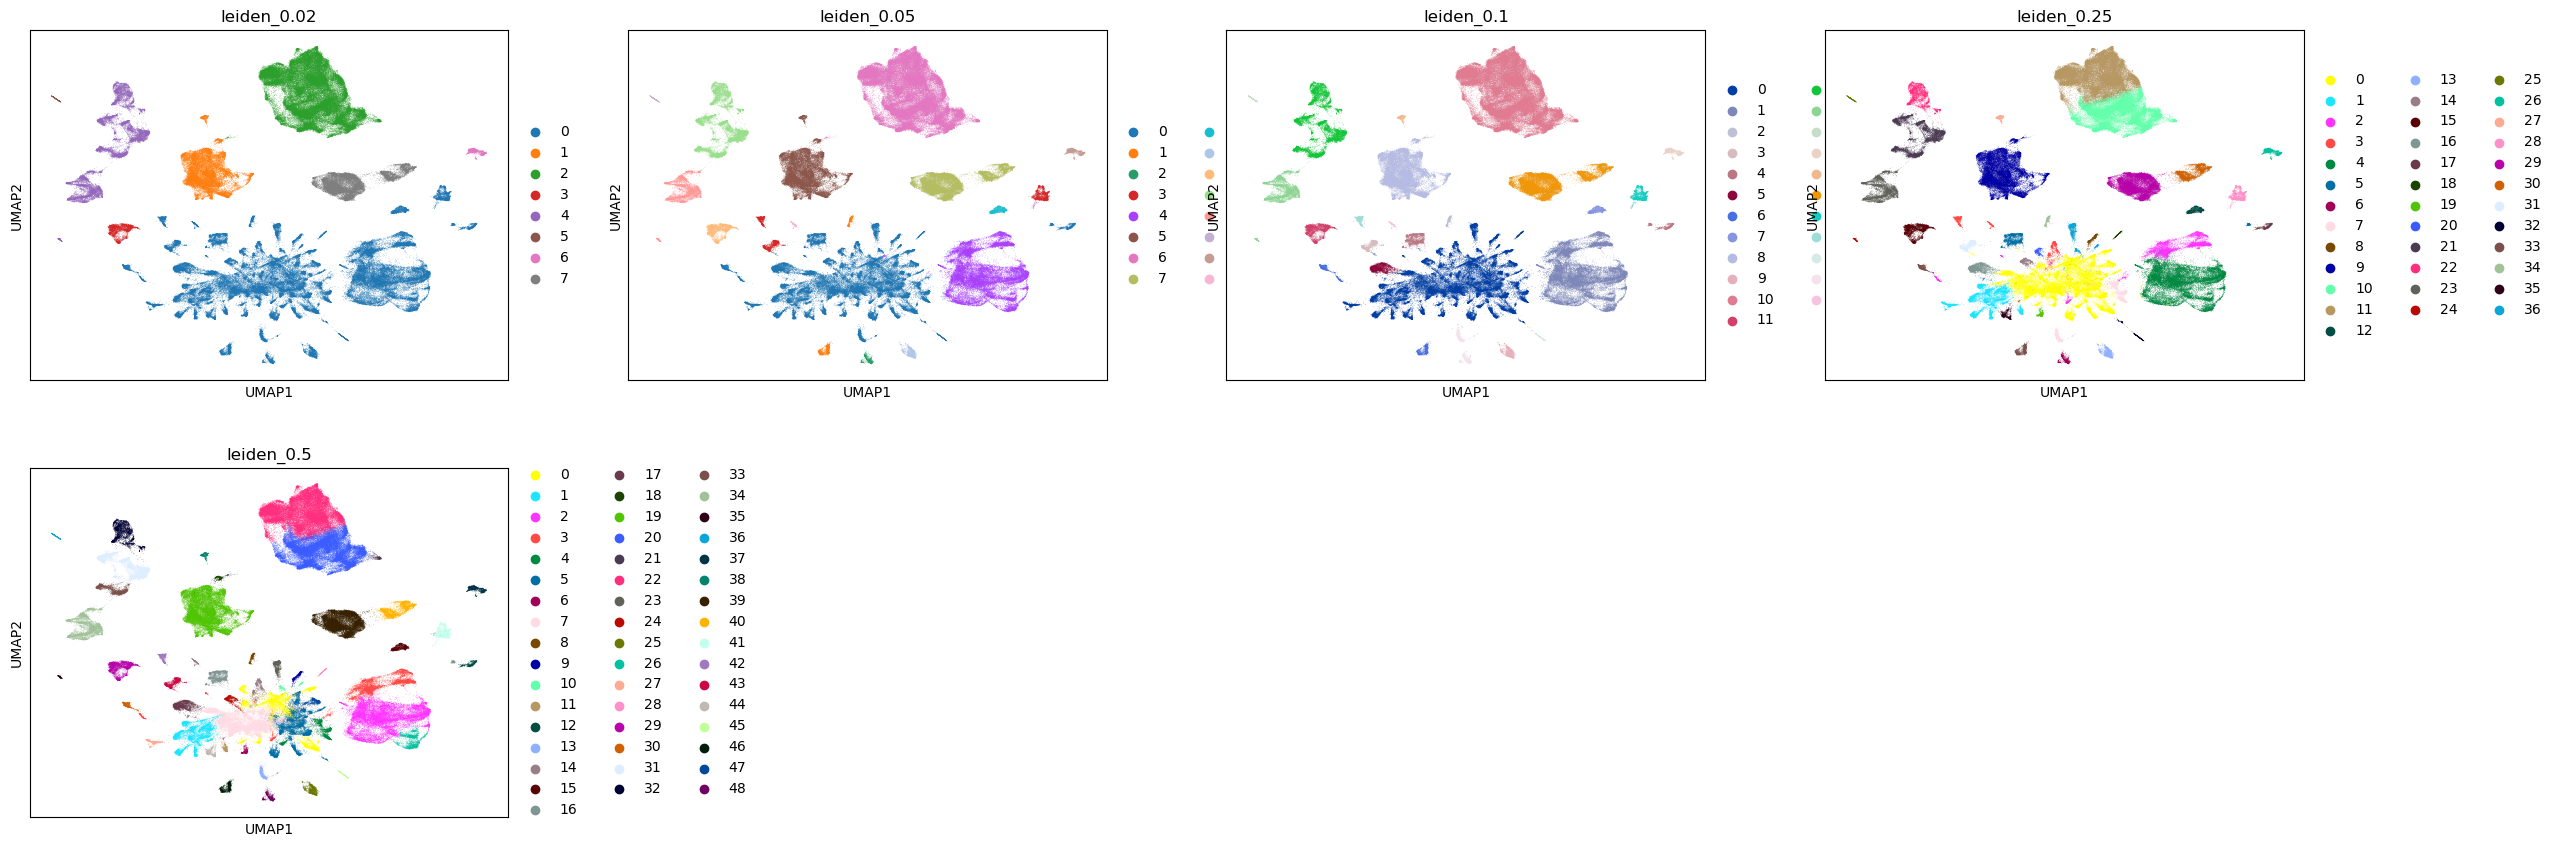

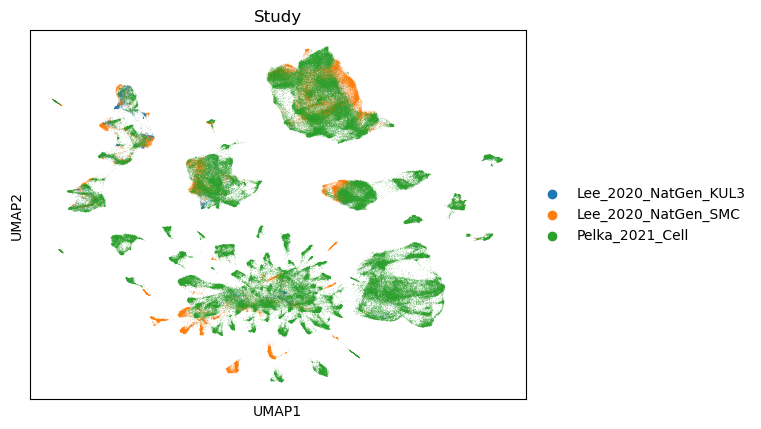

In [9]:
sc.pl.umap(adata, color=["leiden_0.02", "leiden_0.05", "leiden_0.1","leiden_0.25", "leiden_0.5",],)
sc.pl.umap(adata, color='Study',)

保存数据, 准备注释

In [ ]:
adata.write_h5ad(OUTDIR / "ready_for_anno.h5ad", compression="lzf")

/home/zhekai/project/crc-pm/result/fork1-OnlyCRC/ready_for_anno.h5ad
